# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Zaki Nanda Wahyudi | 5054251007 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

# Pengaturan tampilan plot
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
df = pd.read_csv("Mall_Customers.csv")

print("=== 5 Baris Pertama ===")
display(df.head())

print("\n=== Jumlah Baris dan Kolom ===")
print(f"Baris: {df.shape[0]}, Kolom: {df.shape[1]}")

print("\n=== Tipe Data ===")
print(df.dtypes)

print("\n=== Statistik Deskriptif ===")
display(df.describe())

print("\n=== Jumlah Missing Value per Kolom ===")
print(df.isnull().sum())

print("\n=== Jumlah Baris Duplikat ===")
print(df.duplicated().sum())

=== 5 Baris Pertama ===


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



=== Jumlah Baris dan Kolom ===
Baris: 200, Kolom: 5

=== Tipe Data ===
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

=== Statistik Deskriptif ===


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



=== Jumlah Missing Value per Kolom ===
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

=== Jumlah Baris Duplikat ===
0


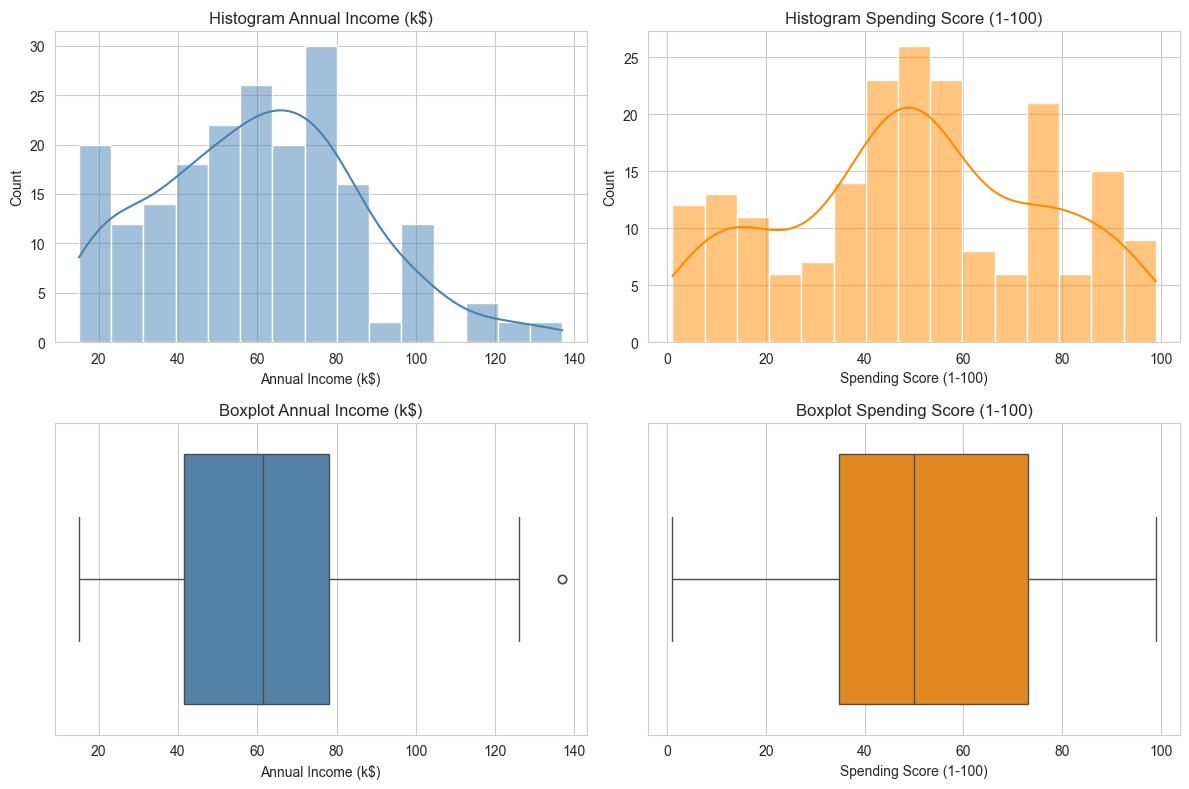

Annual Income (k$): skewness = 0.322, jumlah outlier (IQR) = 2, nilai = [137, 137]
Spending Score (1-100): skewness = -0.047, jumlah outlier (IQR) = 0, nilai = []


In [ ]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
fitur = ["Annual Income (k$)", "Spending Score (1-100)"]
warna = ["steelblue", "darkorange"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, (kolom, c) in enumerate(zip(fitur, warna)):
    # Histogram + KDE
    sns.histplot(df[kolom], bins=15, kde=True, color=c, ax=axes[0, i])
    axes[0, i].set_title(f"Histogram {kolom}")
    axes[0, i].set_xlabel(kolom)

    # Boxplot
    sns.boxplot(x=df[kolom], color=c, ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot {kolom}")
    axes[1, i].set_xlabel(kolom)

plt.tight_layout()
plt.show()

# Pendukung pengamatan: skewness dan outlier berdasarkan aturan IQR
for kolom in fitur:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier = df[(df[kolom] < batas_bawah) | (df[kolom] > batas_atas)][kolom]
    print(f"{kolom}: skewness = {df[kolom].skew():.3f}, "
          f"jumlah outlier (IQR) = {len(outlier)}, nilai = {outlier.tolist()}")

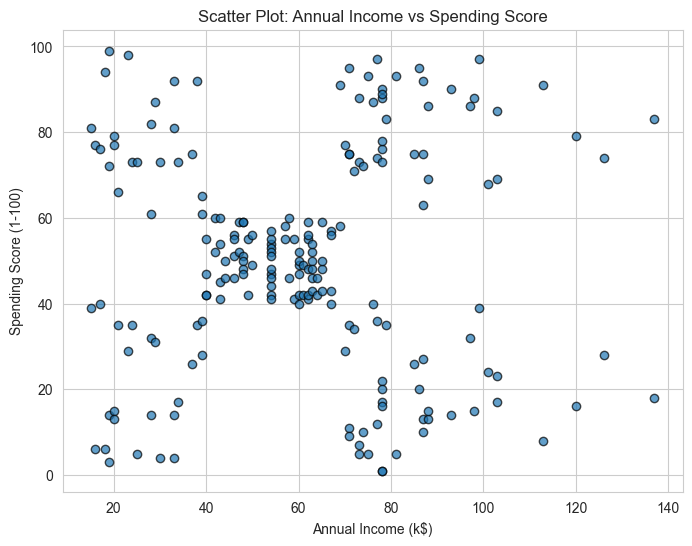

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.
plt.figure(figsize=(8, 6))
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.7,
    edgecolor="k",
)
plt.title("Scatter Plot: Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**

1. **Missing value dan duplikat:** Tidak ada. Semua kolom memiliki 0 missing value dan jumlah baris duplikat juga 0, dari total 200 baris, sehingga data bisa langsung dipakai tanpa pembersihan.

2. **Rentang fitur:**
   - `Annual Income (k$)` berkisar 15–137 dengan median ≈ 61,5. Distribusinya sedikit miring ke kanan (skewness ≈ 0,32), dan ada 2 outlier di 137 k$ menurut aturan IQR. Keduanya pelanggan berpendapatan tinggi yang wajar, bukan kesalahan data.
   - `Spending Score (1-100)` berkisar 1–99 dengan median 50. Distribusinya hampir simetris (skewness ≈ -0,05) dan tidak ada outlier.

3. **Kelompok terpisah:** Ya, sebagian. Pada scatter plot terlihat sekitar **lima kelompok**: satu kelompok padat di tengah (pendapatan dan spending sedang) dan empat kelompok di sudut (pendapatan rendah/tinggi dikombinasikan dengan spending rendah/tinggi). Pemisahannya belum sepenuhnya tegas, karena ada titik di area peralihan, terutama di sekitar pendapatan 70–80 k$. Histogram dan boxplot tiap fitur saja tidak memperlihatkan kelompok ini, jadi strukturnya baru terlihat ketika kedua fitur dilihat bersamaan.

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()

print("\nBentuk X:", X.shape)
display(X.head())

Missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0

Bentuk X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("5 baris pertama X_scaled:")
display(X_scaled.head())

print("\nStatistik deskriptif X_scaled:")
display(X_scaled.describe())

5 baris pertama X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Statistik deskriptif X_scaled:


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


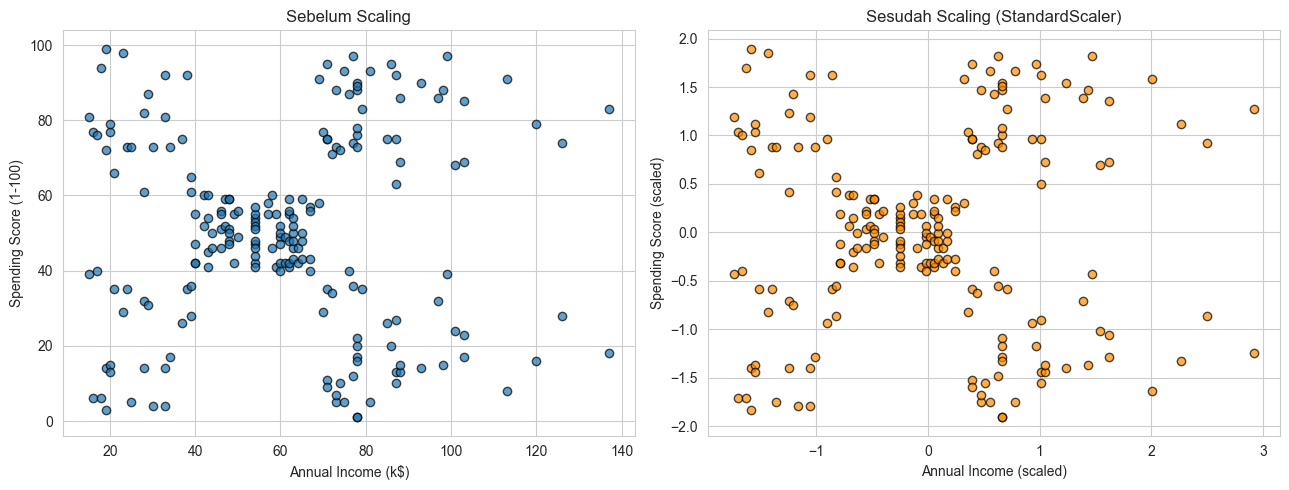

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"],
                alpha=0.7, edgecolor="k")
axes[0].set_title("Sebelum Scaling")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")

axes[1].scatter(X_scaled["Annual Income (k$)"], X_scaled["Spending Score (1-100)"],
                alpha=0.7, edgecolor="k", color="darkorange")
axes[1].set_title("Sesudah Scaling (StandardScaler)")
axes[1].set_xlabel("Annual Income (scaled)")
axes[1].set_ylabel("Spending Score (scaled)")

plt.tight_layout()
plt.show()

**Mengapa scaling penting?**

- **Bentuk sebaran tidak berubah, hanya skalanya.** Kedua plot terlihat sama persis. Yang berbeda hanya angka di sumbu: sebelum scaling dalam satuan asli (k$ dan skor 1–100), sesudahnya berpusat di 0 dengan simpangan baku ≈ 1.
- **Algoritma berbasis jarak sensitif terhadap skala fitur.** DBSCAN (`eps`), BIRCH (`threshold`), dan GMM (kovarians) bekerja dengan jarak atau sebaran data. Fitur dengan rentang lebih besar akan mendominasi perhitungan jarak, sehingga pengaruh fitur lain mengecil.
- **Pada dataset ini efeknya relatif kecil**, karena rentang kedua fitur sudah mirip (Income 15–137, Spending 1–99). Scaling tetap dilakukan sebagai praktik standar dan agar kedua fitur setara jika kelak ditambah fitur lain, misalnya `Age` yang rentangnya jauh berbeda.
- **Parameter menjadi lebih mudah dipilih.** Nilai seperti `eps=0.3` atau `threshold=0.5` hanya bermakna jika data berada pada skala yang diketahui. Setelah scaling, jarak 0,3 berarti sekitar 0,3 simpangan baku, bukan 0,3 k$.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Jawaban:**

- **Alasan memilih kedua fitur:**
  - Keduanya numerik dan kontinu, sehingga cocok untuk algoritma berbasis jarak dan distribusi seperti DBSCAN, BIRCH, dan GMM.
  - Keduanya relevan secara bisnis. Pendapatan menggambarkan daya beli pelanggan, sedangkan spending score menggambarkan perilaku belanjanya. Kombinasi keduanya menghasilkan segmen yang mudah dimaknai.
  - Dengan dua fitur, hasil clustering bisa langsung divisualisasikan pada scatter plot 2D. Pada EDA, kombinasi ini juga memperlihatkan sekitar lima kelompok, yang tidak terlihat dari tiap fitur secara terpisah.

- **Alasan `CustomerID` tidak digunakan:**
  - `CustomerID` hanya nomor urut identitas (1–200) yang tidak mengandung informasi tentang karakteristik pelanggan.
  - Jika dimasukkan, algoritma akan menghitung kemiripan berdasarkan nomor urut, sehingga hasil clustering bisa terdistorsi oleh sesuatu yang tidak bermakna.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

print("Label unik:", np.unique(labels_dbscan))

Label unik: [-1  0  1  2  3  4  5  6]


In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
print("Jumlah anggota per label:")
print(pd.Series(labels_dbscan).value_counts().sort_index())

n_cluster_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = list(labels_dbscan).count(-1)

print(f"\nJumlah cluster (tanpa noise): {n_cluster_dbscan}")
print(f"Jumlah titik noise (label -1): {n_noise_dbscan}")

Jumlah anggota per label:
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah titik noise (label -1): 35


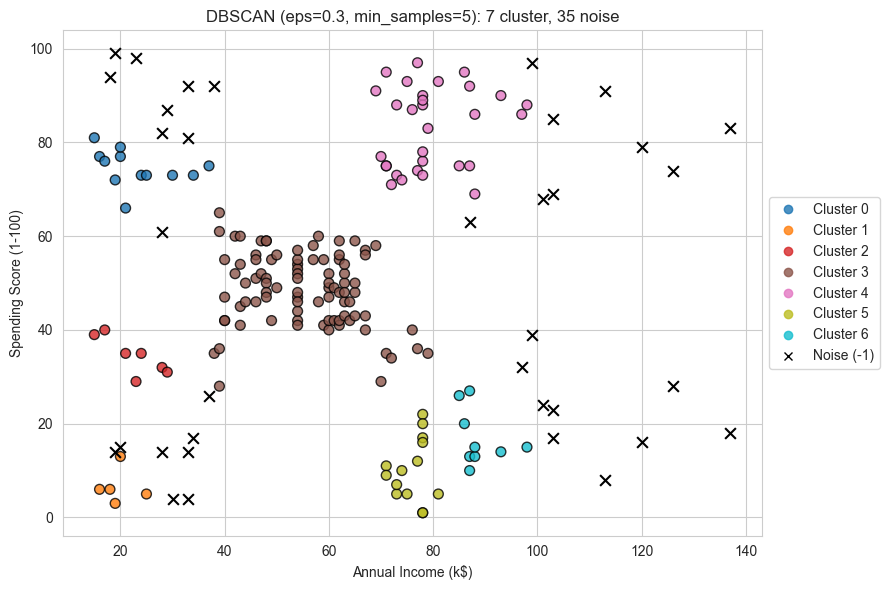

In [11]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.
plt.figure(figsize=(9, 6))

mask_cluster = labels_dbscan != -1
scatter = plt.scatter(
    X.loc[mask_cluster, "Annual Income (k$)"],
    X.loc[mask_cluster, "Spending Score (1-100)"],
    c=labels_dbscan[mask_cluster],
    cmap="tab10",
    s=50,
    edgecolor="k",
    alpha=0.8,
)

mask_noise = labels_dbscan == -1
plt.scatter(
    X.loc[mask_noise, "Annual Income (k$)"],
    X.loc[mask_noise, "Spending Score (1-100)"],
    c="black",
    marker="x",
    s=60,
    label="Noise (-1)",
)

plt.title(f"DBSCAN (eps=0.3, min_samples=5): {n_cluster_dbscan} cluster, {n_noise_dbscan} noise")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(handles=scatter.legend_elements()[0] + [plt.Line2D([], [], color="black", marker="x", linestyle="")],
           labels=[f"Cluster {i}" for i in sorted(set(labels_dbscan) - {-1})] + ["Noise (-1)"],
           loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

In [12]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
daftar_eps = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]
daftar_min_samples = [3, 5, 8, 10]

hasil_dbscan = []
for eps in daftar_eps:
    for ms in daftar_min_samples:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)

        n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        # Silhouette dihitung pada titik non-noise, hanya jika valid
        mask = labels != -1
        if n_cluster >= 2 and mask.sum() > n_cluster:
            sil = silhouette_score(X_scaled[mask], labels[mask])
        else:
            sil = np.nan

        hasil_dbscan.append({
            "eps": eps,
            "min_samples": ms,
            "jumlah_cluster": n_cluster,
            "jumlah_noise": n_noise,
            "silhouette": round(sil, 3) if not np.isnan(sil) else np.nan,
        })

df_dbscan = pd.DataFrame(hasil_dbscan)
display(df_dbscan)

,eps,min_samples,jumlah_cluster,jumlah_noise,silhouette
0,0.2,3,13,44,0.470
1,0.2,5,7,77,0.586
2,0.2,8,2,116,0.603
3,0.2,10,1,129,NaN
4,0.3,3,9,14,0.472
5,0.3,5,7,35,0.524
6,0.3,8,5,72,0.593
7,0.3,10,4,88,0.607
8,0.4,3,4,10,0.395
9,0.4,5,4,15,0.478


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban:**

1. Semakin besar `eps`, jumlah noise turun dan cluster yang berdekatan mulai menyatu, sehingga jumlah cluster berkurang. Pada `min_samples=5`, `eps` naik dari 0,2 ke 0,8 membuat noise turun dari 77 menjadi 0 dan jumlah cluster turun dari 7 menjadi 1 (`eps=0.3`: 7 cluster, 35 noise; `eps=0.4`: 4 cluster, 15 noise; `eps=0.5`: 2 cluster, 8 noise). Pada `eps` yang terlalu kecil jumlah cluster juga bisa turun (misalnya `min_samples=8` dengan `eps=0.2` hanya 2 cluster), karena banyak titik tidak memenuhi syarat kepadatan dan menjadi noise.

2. Semakin besar `min_samples`, syarat kepadatan makin ketat, sehingga noise bertambah dan cluster kecil hilang. Pada `eps=0.3`, `min_samples` naik dari 3 ke 10 membuat noise naik dari 14 menjadi 88 dan jumlah cluster turun dari 9 menjadi 4. Sebaliknya, `min_samples` kecil menghasilkan banyak cluster kecil yang kurang bermakna (13 cluster pada `eps=0.2, min_samples=3`).

3. Ya, ada keduanya:
   - **Satu cluster besar:** semua kombinasi dengan `eps ≥ 0.6` menggabungkan seluruh data menjadi satu cluster, sehingga struktur kelompok tidak terlihat. `eps=0.5` dengan `min_samples` 3, 5, dan 8 juga hanya menghasilkan 2 cluster.
   - **Terlalu banyak noise:** `eps=0.2, min_samples=10` (129 noise, 64,5%) dan `eps=0.2, min_samples=8` (116 noise, 58%). Kombinasi `eps=0.3` dengan `min_samples` 8 dan 10 (72 dan 88 noise) juga membuang sepertiga sampai hampir separuh data.
   - **Kombinasi yang seimbang:** `eps=0.4, min_samples=8` menghasilkan 5 cluster dengan 25 noise (12,5%) dan silhouette 0,549, sesuai dengan lima kelompok pada scatter plot.
   - Silhouette dihitung hanya pada titik non-noise, sehingga nilainya cenderung tinggi pada kombinasi dengan noise besar. Karena itu silhouette tidak boleh dipakai sendirian untuk memilih parameter.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [13]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

print("Label unik:", np.unique(labels_birch))
print("Jumlah subcluster di CF-tree:", len(birch.subcluster_centers_))

Label unik: [0 1 2 3 4]
Jumlah subcluster di CF-tree: 10


In [14]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
print("Jumlah anggota per cluster:")
print(pd.Series(labels_birch).value_counts().sort_index())

n_cluster_birch = len(set(labels_birch))
print(f"\nJumlah cluster yang terbentuk: {n_cluster_birch}")

Jumlah anggota per cluster:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

Jumlah cluster yang terbentuk: 5


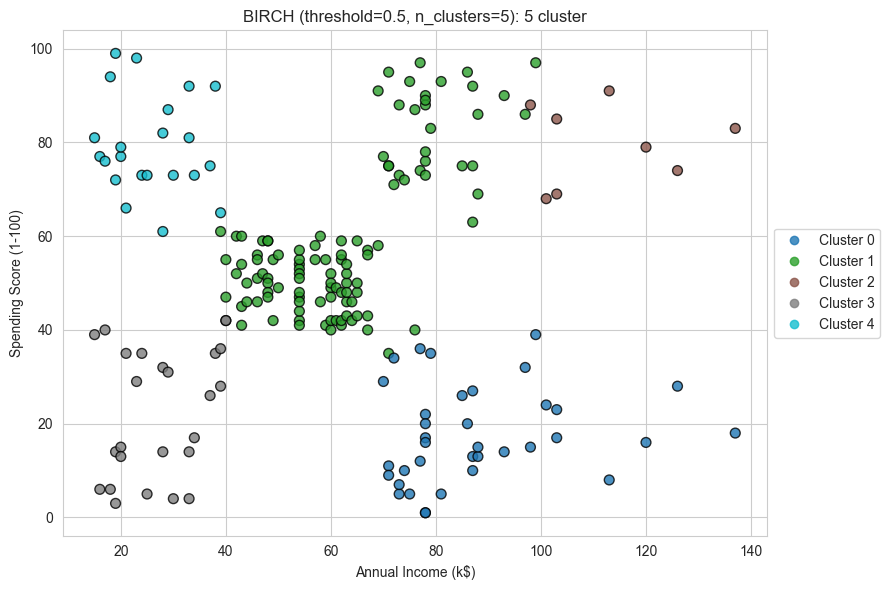

In [15]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=labels_birch,
    cmap="tab10",
    s=50,
    edgecolor="k",
    alpha=0.8,
)

plt.title(f"BIRCH (threshold=0.5, n_clusters=5): {n_cluster_birch} cluster")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=[f"Cluster {i}" for i in sorted(set(labels_birch))],
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)
plt.tight_layout()
plt.show()

In [16]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
daftar_threshold = [0.3, 0.5, 0.7, 1.0]

hasil_birch = []
for t in daftar_threshold:
    model = Birch(threshold=t, n_clusters=5)
    labels = model.fit_predict(X_scaled)

    n_cluster = len(set(labels))
    n_subcluster = len(model.subcluster_centers_)
    sil = silhouette_score(X_scaled, labels) if n_cluster >= 2 else np.nan

    hasil_birch.append({
        "threshold": t,
        "jumlah_subcluster": n_subcluster,
        "jumlah_cluster": n_cluster,
        "silhouette": round(sil, 3) if not np.isnan(sil) else np.nan,
    })

df_birch = pd.DataFrame(hasil_birch)
display(df_birch)

,threshold,jumlah_subcluster,jumlah_cluster,silhouette
0,0.3,23,5,0.478
1,0.5,10,5,0.414
2,0.7,6,5,0.421
3,1.0,4,4,0.389


In [17]:
# Jumlah cluster BIRCH tanpa n_clusters (hanya subcluster dari CF-tree)
for t in [0.3, 0.5, 0.7, 1.0]:
    m = Birch(threshold=t, n_clusters=None).fit(X_scaled)
    print(f"threshold={t}: {len(set(m.labels_))} cluster, "
          f"silhouette={silhouette_score(X_scaled, m.labels_):.3f}")

threshold=0.3: 23 cluster, silhouette=0.414
threshold=0.5: 10 cluster, silhouette=0.477
threshold=0.7: 6 cluster, silhouette=0.486
threshold=1.0: 4 cluster, silhouette=0.389


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**

1. Semakin besar `threshold`, jumlah cluster semakin sedikit. Tanpa `n_clusters`, `threshold` 0,3 / 0,5 / 0,7 / 1,0 menghasilkan 23 / 10 / 6 / 4 cluster. Penyebabnya, `threshold` yang besar membuat titik yang lebih berjauhan bisa digabung ke satu subcluster, sehingga CF-tree punya lebih sedikit subcluster. Silhouette tidak naik terus: nilainya tertinggi di `threshold=0.7` (0,486) lalu turun di 1,0 (0,389), karena pada 1,0 kelompok yang seharusnya terpisah mulai menyatu.

2. DBSCAN menandai titik yang jauh dari area padat sebagai noise (label -1), sehingga titik tersebut tidak masuk cluster mana pun. BIRCH tidak punya konsep noise: setiap titik pasti masuk ke suatu cluster. Titik yang jauh akan digabung ke cluster terdekat, sehingga ikut memengaruhi pusat dan sebarannya, atau membentuk cluster kecil sendiri. Hal ini terlihat pada hasil kita: `threshold=0.5` menghasilkan satu cluster berisi hanya 8 titik dan `threshold=0.3` menghasilkan cluster berisi 3 titik, padahal titik-titik itu berada di tepi kelompok pendapatan tinggi.

3. Ya, berubah. Tanpa `n_clusters`, jumlah cluster mengikuti jumlah subcluster dari CF-tree dan bisa sangat banyak (10 pada `threshold=0.5`). Dengan `n_clusters=5`, subcluster tersebut digabung lagi pada tahap kedua sehingga hasil akhirnya 5 cluster untuk `threshold` 0,3 / 0,5 / 0,7. `n_clusters` tidak bisa memaksa jumlah cluster melebihi jumlah subcluster: pada `threshold=1.0` hanya ada 4 subcluster, sehingga hasilnya tetap 4 cluster meskipun diminta 5.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [18]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)

labels_gmm = gmm.predict(X_scaled)

print("Label unik:", np.unique(labels_gmm))
print("EM konvergen:", gmm.converged_)
print("Jumlah iterasi EM:", gmm.n_iter_)

Label unik: [0 1 2 3 4]
EM konvergen: True
Jumlah iterasi EM: 5


In [19]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.
print("Jumlah anggota per cluster:")
print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm.predict_proba(X_scaled)
df_proba = pd.DataFrame(proba, columns=[f"Cluster_{i}" for i in range(gmm.n_components)])

print("\n5 baris pertama probabilitas keanggotaan:")
display(df_proba.head().round(3))

max_proba = proba.max(axis=1)
idx_tidak_pasti = np.where(max_proba < 0.8)[0]

print(f"\nProbabilitas tertinggi rata-rata: {max_proba.mean():.3f}")
print(f"Jumlah titik dengan probabilitas tertinggi < 0.8: {len(idx_tidak_pasti)}")

df_tidak_pasti = df_proba.iloc[idx_tidak_pasti].round(3).copy()
df_tidak_pasti["label"] = labels_gmm[idx_tidak_pasti]
df_tidak_pasti["prob_max"] = max_proba[idx_tidak_pasti].round(3)
df_tidak_pasti["Annual Income (k$)"] = X.iloc[idx_tidak_pasti, 0].values
df_tidak_pasti["Spending Score (1-100)"] = X.iloc[idx_tidak_pasti, 1].values
display(df_tidak_pasti.sort_values("prob_max"))

Jumlah anggota per cluster:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

5 baris pertama probabilitas keanggotaan:


,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4
0,0.0,0.0,0.001,0.0,0.999
1,0.0,0.0,1.000,0.0,0.000
2,0.0,0.0,0.000,0.0,1.000
3,0.0,0.0,1.000,0.0,0.000
4,0.0,0.0,0.002,0.0,0.998



Probabilitas tertinggi rata-rata: 0.983
Jumlah titik dengan probabilitas tertinggi < 0.8: 6


,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,label,prob_max,Annual Income (k$),Spending Score (1-100)
124,0.497,0.0,0.000,0.503,0.000,3,0.503,70,29
48,0.611,0.0,0.000,0.000,0.388,0,0.611,40,42
49,0.611,0.0,0.000,0.000,0.388,0,0.611,40,42
27,0.279,0.0,0.675,0.000,0.046,2,0.675,28,61
160,0.772,0.0,0.000,0.228,0.000,0,0.772,79,35
55,0.796,0.0,0.000,0.000,0.204,0,0.796,43,41


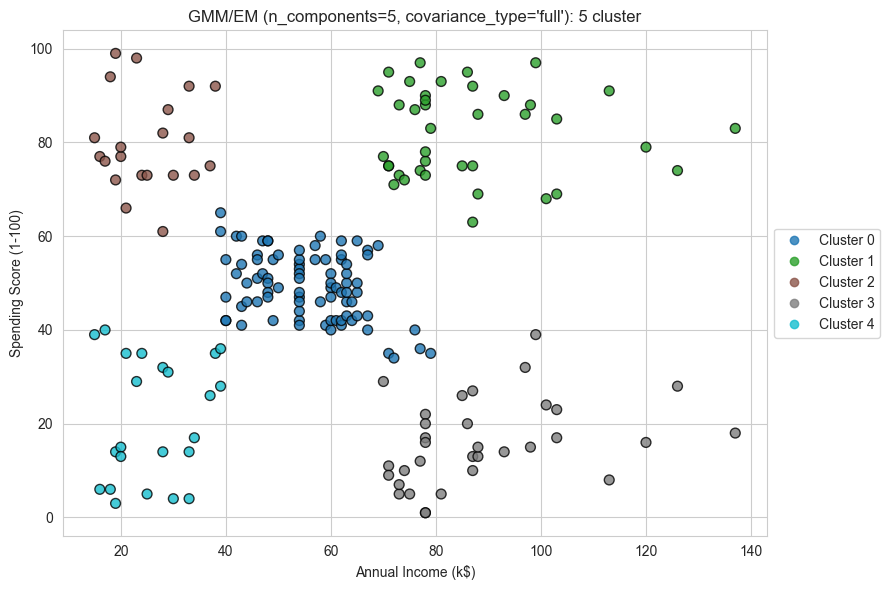

In [20]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.
n_cluster_gmm = len(set(labels_gmm))

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=labels_gmm,
    cmap="tab10",
    s=50,
    edgecolor="k",
    alpha=0.8,
)

plt.title(f"GMM/EM (n_components=5, covariance_type='full'): {n_cluster_gmm} cluster")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=[f"Cluster {i}" for i in sorted(set(labels_gmm))],
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)
plt.tight_layout()
plt.show()

In [21]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.
hasil_gmm = []
for k in range(2, 9):
    model = GaussianMixture(n_components=k, covariance_type="full", random_state=42)
    model.fit(X_scaled)
    labels = model.predict(X_scaled)

    hasil_gmm.append({
        "n_components": k,
        "silhouette": round(silhouette_score(X_scaled, labels), 3),
        "BIC": round(model.bic(X_scaled), 1),
    })

df_gmm = pd.DataFrame(hasil_gmm)
display(df_gmm)

,n_components,silhouette,BIC
0,2,0.379,1153.9
1,3,0.430,1151.7
2,4,0.413,1103.8
3,5,0.554,1058.7
4,6,0.517,1074.7
5,7,0.509,1087.3
6,8,0.430,1102.4


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban:**

1. Probabilitas keanggotaan (`predict_proba`) menyatakan seberapa besar kemungkinan sebuah titik berasal dari tiap komponen Gaussian, dan jumlahnya untuk satu titik adalah 1. Ini disebut soft clustering, berbeda dari DBSCAN dan BIRCH yang memberi satu label tegas. Label akhir diambil dari komponen dengan probabilitas terbesar. Pada hasil kita, rata-rata probabilitas tertinggi adalah 0,983, jadi sebagian besar titik masuk ke satu komponen dengan sangat yakin. Hanya 6 titik yang probabilitas tertingginya di bawah 0,8, dan semuanya berada di area peralihan antar kelompok. Contohnya titik index 124 (income 70, spending 29) yang terbagi hampir sama antara cluster 0 (0,497) dan cluster 3 (0,503). Dalam algoritma EM, probabilitas ini dipakai pada langkah E (*expectation*) sebagai bobot tiap titik terhadap tiap komponen. Pada langkah M (*maximization*), bobot tersebut dipakai untuk memperbarui rata-rata, kovarians, dan proporsi komponen. Kedua langkah diulang sampai konvergen (pada model awal kita 5 iterasi).

2. Perubahan `n_components` mengubah banyaknya distribusi Gaussian yang dipakai untuk memodelkan data. Jika terlalu sedikit (k=2 atau 3), beberapa kelompok digabung dalam satu komponen sehingga model kurang cocok dengan data (silhouette 0,379 dan 0,430, BIC 1153,9 dan 1151,7). Jika terlalu banyak (k=6 sampai 8), kelompok yang sebenarnya satu terpecah menjadi beberapa komponen, kompleksitas model naik tanpa tambahan kecocokan yang sebanding (BIC naik ke 1074,7, 1087,3, dan 1102,4). Hasil terbaik muncul di k=5.

3. Karena GMM adalah model probabilistik dengan struktur tetap: model harus tahu lebih dulu berapa komponen Gaussian yang akan diestimasi parameternya (rata-rata, kovarians, bobot). Algoritma EM hanya mengoptimalkan parameter komponen yang sudah ditentukan, bukan mencari jumlah komponen itu sendiri. Karena itu jumlah cluster dipilih lewat perbandingan beberapa nilai `n_components`, dengan kriteria seperti BIC dan silhouette, seperti yang kita lakukan pada sel eksperimen. Berbeda dengan DBSCAN yang menentukan jumlah cluster dari kepadatan data.

4. Ya, pada dataset ini keduanya sepakat. Silhouette tertinggi (0,554) dan BIC terendah (1058,7) sama-sama berada di `n_components=5`. Kesepakatan ini tidak selalu terjadi, karena BIC menilai kecocokan model terhadap distribusi data dengan penalti kompleksitas, sedangkan silhouette menilai keterpisahan dan kekompakan cluster. Kesepakatan di sini sejalan dengan scatter plot yang menunjukkan lima kelompok.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [22]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
def evaluasi_clustering(X_data, labels):
    X_arr = np.asarray(X_data)
    labels = np.asarray(labels)

    # Keluarkan titik noise
    mask = labels != -1
    X_eval, labels_eval = X_arr[mask], labels[mask]

    n_cluster = len(set(labels_eval))
    n_noise = int((~mask).sum())

    hasil = {
        "jumlah_cluster": n_cluster,
        "jumlah_noise": n_noise,
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
    }

    # Metrik hanya valid jika cluster >= 2 dan cluster < jumlah titik yang dievaluasi
    if n_cluster >= 2 and n_cluster < len(X_eval):
        hasil["silhouette"] = silhouette_score(X_eval, labels_eval)
        hasil["davies_bouldin"] = davies_bouldin_score(X_eval, labels_eval)
        hasil["calinski_harabasz"] = calinski_harabasz_score(X_eval, labels_eval)

    return hasil

In [23]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# DBSCAN: eps=0.4, min_samples=8 -> 5 cluster dengan noise relatif kecil
labels_dbscan_best = DBSCAN(eps=0.4, min_samples=8).fit_predict(X_scaled)

# BIRCH: threshold=0.3, n_clusters=5 -> silhouette tertinggi pada tabel threshold
labels_birch_best = Birch(threshold=0.3, n_clusters=5).fit_predict(X_scaled)

# GMM: n_components=5 -> silhouette tertinggi dan BIC terendah
labels_gmm_best = GaussianMixture(
    n_components=5, covariance_type="full", random_state=42
).fit_predict(X_scaled)

# Evaluasi dengan fungsi evaluasi_clustering
daftar_model = {
    "DBSCAN (eps=0.4, min_samples=8)": labels_dbscan_best,
    "BIRCH (threshold=0.3, n_clusters=5)": labels_birch_best,
    "GMM (n_components=5)": labels_gmm_best,
}

baris = []
for nama, labels in daftar_model.items():
    h = evaluasi_clustering(X_scaled, labels)
    baris.append({
        "model": nama,
        "jumlah_cluster": h["jumlah_cluster"],
        "jumlah_noise": h["jumlah_noise"] if "DBSCAN" in nama else "N/A",
        "silhouette": round(h["silhouette"], 3),
        "davies_bouldin": round(h["davies_bouldin"], 3),
        "calinski_harabasz": round(h["calinski_harabasz"], 1),
    })

df_evaluasi = pd.DataFrame(baris)
display(df_evaluasi)

,model,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
0,"DBSCAN (eps=0.4, min_samples=8)",5,25,0.549,0.501,222.1
1,"BIRCH (threshold=0.3, n_clusters=5)",5,N/A,0.478,0.648,144.0
2,GMM (n_components=5),5,N/A,0.554,0.576,244.9


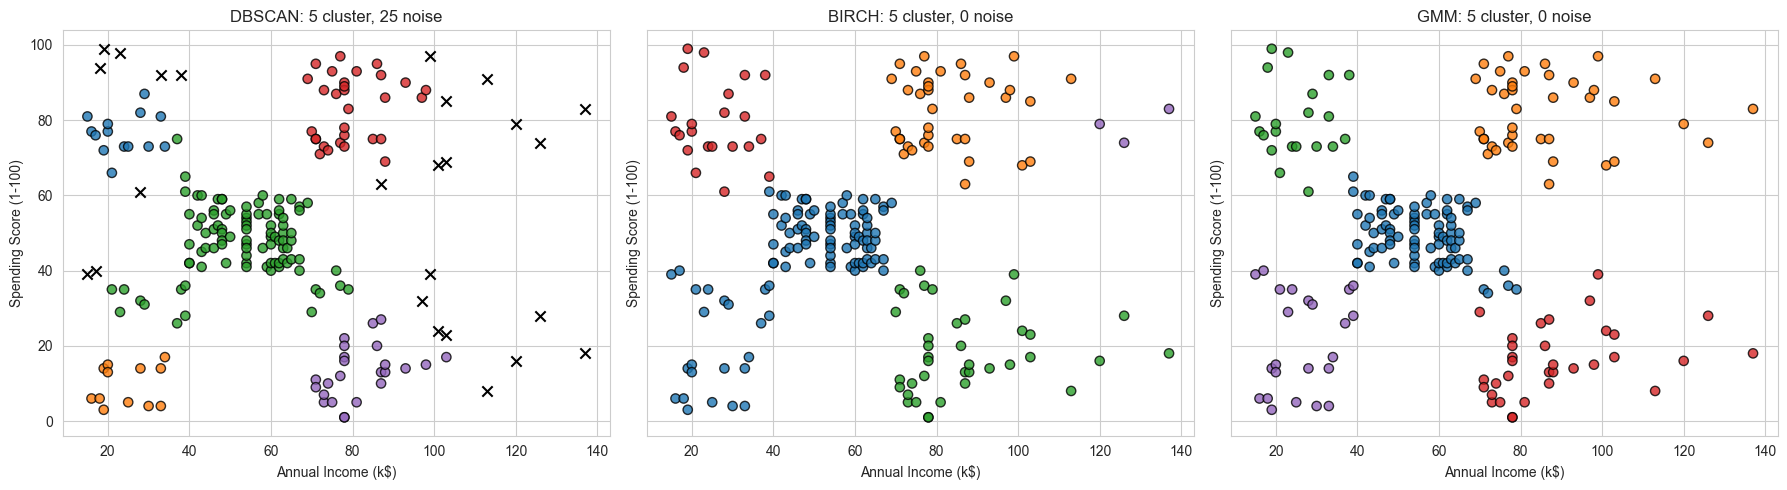

In [24]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.
hasil_plot = [
    ("DBSCAN", labels_dbscan_best),
    ("BIRCH", labels_birch_best),
    ("GMM", labels_gmm_best),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (nama, labels) in zip(axes, hasil_plot):
    mask_cluster = labels != -1
    mask_noise = labels == -1
    n_cluster = len(set(labels[mask_cluster]))
    n_noise = int(mask_noise.sum())

    # Titik cluster
    ax.scatter(
        X.loc[mask_cluster, "Annual Income (k$)"],
        X.loc[mask_cluster, "Spending Score (1-100)"],
        c=labels[mask_cluster],
        cmap="tab10",
        vmin=0,
        vmax=9,
        s=45,
        edgecolor="k",
        alpha=0.8,
    )

    # Titik noise (hanya ada pada DBSCAN)
    if n_noise > 0:
        ax.scatter(
            X.loc[mask_noise, "Annual Income (k$)"],
            X.loc[mask_noise, "Spending Score (1-100)"],
            c="black",
            marker="x",
            s=55,
        )

    ax.set_title(f"{nama}: {n_cluster} cluster, {n_noise} noise")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

In [25]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.
def profil_cluster(X_data, labels, nama_model):
    d = X_data.copy()
    d["label"] = labels

    profil = d.groupby("label").agg(
        jumlah_anggota=("label", "size"),
        income_median=("Annual Income (k$)", "median"),
        income_mean=("Annual Income (k$)", "mean"),
        spending_median=("Spending Score (1-100)", "median"),
        spending_mean=("Spending Score (1-100)", "mean"),
    ).round(1)

    print(f"=== Profil Cluster {nama_model} ===")
    # Cluster biasa
    display(profil[profil.index != -1])
    # Noise dianalisis terpisah (jika ada)
    if -1 in profil.index:
        print("Noise (label -1):")
        display(profil.loc[[-1]])
    print()

profil_cluster(X, labels_dbscan_best, "DBSCAN (eps=0.4, min_samples=8)")
profil_cluster(X, labels_birch_best, "BIRCH (threshold=0.3, n_clusters=5)")
profil_cluster(X, labels_gmm_best, "GMM (n_components=5)")

=== Profil Cluster DBSCAN (eps=0.4, min_samples=8) ===


,jumlah_anggota,income_median,income_mean,spending_median,spending_mean
label,,,,,
0,14,22.5,23.6,76.5,76.4
1,12,22.5,24.6,9.5,9.6
2,95,54.0,53.3,48.0,47.8
3,30,78.0,79.5,86.0,83.1
4,24,78.0,81.9,13.0,13.0


Noise (label -1):


,jumlah_anggota,income_median,income_mean,spending_median,spending_mean
label,,,,,
-1,25,101.0,83.0,68.0,60.5



=== Profil Cluster BIRCH (threshold=0.3, n_clusters=5) ===


,jumlah_anggota,income_median,income_mean,spending_median,spending_mean
label,,,,,
0,101,50.0,48.2,47.0,43.4
1,36,78.0,83.1,85.5,82.4
2,38,80.0,87.0,16.5,18.6
3,22,24.5,25.7,77.0,79.4
4,3,126.0,127.7,79.0,78.7



=== Profil Cluster GMM (n_components=5) ===


,jumlah_anggota,income_median,income_mean,spending_median,spending_mean
label,,,,,
0,84,55.5,55.6,49.5,49.4
1,39,79.0,86.5,83.0,82.1
2,21,24.0,25.1,77.0,80.0
3,33,86.0,88.8,15.0,16.0
4,23,25.0,26.3,17.0,20.9


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster muncul dari kepadatan data (berkisar 1 sampai 13 cluster pada eksperimen kita, tergantung parameter). | Tidak wajib, tetapi untuk hasil akhir yang terkontrol biasanya `n_clusters` ditentukan (kita memakai 5). Tanpa `n_clusters`, jumlah cluster sama dengan jumlah subcluster CF-tree (23, 10, 6, 4 pada `threshold` 0,3 / 0,5 / 0,7 / 1,0). | Ya. `n_components` harus ditentukan sebelum training, lalu dipilih dengan membandingkan beberapa nilai memakai BIC dan silhouette (terbaik: 5). |
| Dapat memberi label noise secara eksplisit? | Ya, label -1 (25 titik pada `eps=0.4, min_samples=8`). | Tidak. Semua titik dimasukkan ke suatu cluster. | Tidak secara eksplisit, tetapi probabilitas keanggotaan yang rendah menandai titik tidak pasti (6 titik dengan probabilitas tertinggi < 0,8). |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples`. `eps ≥ 0.6` menyatukan semua titik, sedangkan `eps=0.2, min_samples=10` membuang 129 titik sebagai noise. | `threshold` (menentukan jumlah subcluster) dan `n_clusters` (tahap penggabungan akhir). | `n_components` dan `covariance_type` (serta `random_state` untuk inisialisasi). |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas (tidak harus bulat), selama area-nya cukup padat. | Cenderung bulat atau kompak, karena subcluster dibatasi radius `threshold`. | Elips (Gaussian) dengan ukuran dan orientasi berbeda pada `covariance_type='full'`. |
| Kelebihan | Mendeteksi noise dan outlier, tidak perlu menentukan jumlah cluster, dan Davies-Bouldin terbaik (0,501). | Cepat dan hemat memori karena meringkas data ke dalam CF-tree, sehingga cocok untuk data besar. Semua titik mendapat label. | Menghasilkan probabilitas keanggotaan (*soft clustering*). Silhouette tertinggi (0,554) dan Calinski-Harabasz tertinggi (244,9), dengan ukuran cluster yang paling seimbang (84, 39, 21, 33, 23). |
| Kekurangan | Sangat sensitif terhadap `eps` dan `min_samples`. Noise membuang data (12,5% pada parameter terpilih), dan metrik dihitung tanpa noise sehingga tidak sepenuhnya sebanding. | Tanpa noise, titik jauh ikut membentuk cluster (cluster 3 titik pada `threshold=0.3`). Hasil paling lemah di ketiga metrik (silhouette 0,478) dan ukuran cluster tidak seimbang (101 titik vs 3 titik). | Harus menentukan jumlah komponen di awal dan mengasumsikan data berdistribusi Gaussian. Hasil dapat bergantung pada inisialisasi. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

**Jawaban:**

1. Algoritma yang dipakai bekerja dengan jarak atau sebaran data, sehingga fitur dengan rentang lebih besar akan mendominasi perhitungan. Setelah `StandardScaler`, kedua fitur berpusat di 0 dengan simpangan baku ≈ 1, sehingga pengaruhnya setara. Pada dataset ini perbedaan rentang kedua fitur tidak terlalu besar (Income 15–137, Spending 1–99), sehingga bentuk sebaran pada scatter plot sebelum dan sesudah scaling terlihat sama. Scaling tetap penting karena parameter seperti `eps=0.3` dan `threshold=0.5` baru bermakna jika data berada pada skala yang diketahui (satuan simpangan baku, bukan k$), dan agar hasil tetap sebanding jika kelak ditambah fitur lain seperti `Age`.

2. Kenaikan `eps` membuat noise turun dan cluster yang berdekatan menyatu. Pada `min_samples=5`, `eps` 0,2 / 0,3 / 0,4 / 0,5 menghasilkan 7 / 7 / 4 / 2 cluster dengan noise 77 / 35 / 15 / 8, dan pada `eps ≥ 0.6` hanya tersisa satu cluster. Kenaikan `min_samples` membuat syarat kepadatan lebih ketat sehingga noise bertambah: pada `eps=0.3`, `min_samples` 3 sampai 10 menaikkan noise dari 14 menjadi 88 dan menurunkan cluster dari 9 menjadi 4. Kombinasi `eps=0.2, min_samples=10` menghasilkan 1 cluster dengan 129 noise (64,5%), sedangkan `eps=0.4, min_samples=8` memberikan hasil seimbang: 5 cluster dengan 25 noise (12,5%).

3. `threshold` menentukan jumlah subcluster di CF-tree. Semakin besar nilainya, subcluster semakin sedikit: 23 / 10 / 6 / 4 untuk `threshold` 0,3 / 0,5 / 0,7 / 1,0. `n_clusters` menentukan jumlah cluster akhir lewat penggabungan subcluster, tetapi tidak dapat melebihi jumlah subcluster. Dengan `n_clusters=5`, hasilnya 5 cluster pada `threshold` 0,3 sampai 0,7, tetapi hanya 4 pada `threshold=1.0` karena subcluster-nya hanya 4. Silhouette dengan `n_clusters=5` bernilai 0,478 / 0,414 / 0,421 / 0,389. Ukuran cluster juga tidak seimbang (101, 36, 38, 22, 3 titik pada `threshold=0.3`), jadi `threshold` kecil tidak selalu menghasilkan pembagian yang masuk akal.

4. Probabilitas keanggotaan menyatakan seberapa besar kemungkinan sebuah titik berasal dari tiap komponen Gaussian, dengan jumlah 1 untuk setiap titik (*soft clustering*). Label akhir diambil dari komponen dengan probabilitas terbesar. Pada hasil kita, rata-rata probabilitas tertinggi adalah 0,983, dan hanya 6 titik yang probabilitas tertingginya di bawah 0,8, misalnya titik index 124 yang terbagi hampir sama antara cluster 3 (0,503) dan cluster 0 (0,497). Algoritma EM memakai probabilitas ini pada langkah E sebagai bobot tiap titik terhadap tiap komponen, lalu pada langkah M bobot tersebut dipakai untuk memperbarui rata-rata, kovarians, dan proporsi komponen. Kedua langkah diulang sampai konvergen (5 iterasi pada model `n_components=5`).

5. GMM dengan `n_components=5` paling mudah diinterpretasikan. Kelima komponennya sesuai dengan lima kelompok yang terlihat di scatter plot (tengah, kanan atas, kanan bawah, kiri atas, kiri bawah), ukurannya seimbang (84, 39, 21, 33, 23), dan pusat tiap komponen langsung terbaca dari rata-rata dan median fiturnya. Probabilitas keanggotaan juga memberi informasi tambahan tentang titik di area peralihan. DBSCAN dengan `eps=0.4, min_samples=8` juga menghasilkan 5 segmen yang mirip, tetapi 25 pelanggan berlabel noise tidak membentuk kelompok yang jelas (median income 101 dan rata-rata 83,0), sehingga lebih sulit dimaknai. BIRCH paling sulit karena satu cluster berisi 101 titik yang menggabungkan kelompok tengah dengan sebagian kelompok lain, sedangkan satu cluster lain hanya berisi 3 titik.

6. Tidak sepenuhnya sama. GMM terbaik pada Silhouette (0,554) dan Calinski-Harabasz (244,9), sedangkan DBSCAN terbaik pada Davies-Bouldin (0,501). BIRCH terendah di ketiga metrik (0,478 / 0,648 / 144,0). Kemungkinan penyebab perbedaannya: (a) DBSCAN dievaluasi hanya pada 175 titik non-noise, sedangkan BIRCH dan GMM pada 200 titik, sehingga titik yang sulit dikelompokkan sudah dibuang dan nilainya cenderung lebih baik; (b) tiap metrik mengukur hal berbeda, yaitu Silhouette memakai jarak titik ke cluster, Davies-Bouldin membandingkan sebaran dalam cluster dengan jarak antar pusat, dan Calinski-Harabasz membandingkan variansi antar dan dalam cluster; (c) Calinski-Harabasz dan Davies-Bouldin cenderung menyukai cluster yang kompak dan berbentuk bulat. Metrik ini perlu dibaca bersama visualisasi dan profil cluster, bukan sendirian.

7. Berdasarkan profil GMM (median income, median spending):
   - **Cluster 0 (84 pelanggan; ≈ 55,5 k$, ≈ 49,5): Pelanggan menengah.** Pendapatan dan pengeluaran sedang, kelompok terbesar.
   - **Cluster 1 (39 pelanggan; ≈ 79 k$, ≈ 83): Pelanggan premium.** Pendapatan tinggi dan pengeluaran tinggi, sasaran utama promosi.
   - **Cluster 2 (21 pelanggan; ≈ 24 k$, ≈ 77): Pelanggan muda boros / berpendapatan rendah tapi gemar belanja.** Pendapatan rendah, pengeluaran tinggi.
   - **Cluster 3 (33 pelanggan; ≈ 86 k$, ≈ 15): Pelanggan hemat berpendapatan tinggi.** Mampu membeli, tetapi pengeluarannya rendah, sehingga berpotensi ditingkatkan dengan penawaran khusus.
   - **Cluster 4 (23 pelanggan; ≈ 25 k$, ≈ 17): Pelanggan hemat berpendapatan rendah.** Pendapatan dan pengeluaran sama-sama rendah.

   Profil DBSCAN serupa (cluster tengah 95 pelanggan, cluster kanan atas 30, kanan bawah 24, kiri atas 14, kiri bawah 12), ditambah 25 noise yang campuran. Pada BIRCH (`threshold=0.3`), cluster tengah menyerap sebagian kelompok lain (101 pelanggan, median ≈ 50 k$ dan ≈ 47) dan satu cluster hanya berisi 3 pelanggan berpendapatan sangat tinggi (≈ 126 k$).

8. Dengan hanya dua fitur, segmentasi mengabaikan faktor lain seperti `Age` dan `Gender` yang bisa membedakan perilaku pelanggan (misalnya, dua pelanggan dengan income dan spending sama bisa berbeda usia). Hasil juga hanya merepresentasikan hubungan antara dua variabel, bukan profil pelanggan yang utuh. Dataset berjumlah 200 pelanggan, sehingga cluster kecil mudah tidak stabil: perubahan kecil pada `eps`, `threshold`, atau `n_components` dapat mengubah hasil secara besar (misalnya cluster 3 titik pada BIRCH atau 129 noise pada `eps=0.2`). Metrik internal pada data sekecil ini juga cenderung berfluktuasi, dan hasilnya belum tentu berlaku untuk pelanggan di luar data ini. Terakhir, ada dua pelanggan berpendapatan 137 k$ yang bisa memengaruhi hasil, dan tidak ada label sebenarnya untuk memvalidasi segmen yang terbentuk.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**Jawaban:**

1. **Algoritma paling berguna: EM/GMM.** GMM dengan `n_components=5` memberi Silhouette tertinggi (0,554) dan Calinski-Harabasz tertinggi (244,9), dan BIC-nya terendah (1058,7) di antara `n_components` 2 sampai 8. Kelima cluster-nya sesuai dengan lima kelompok pada scatter plot, ukurannya seimbang (84, 39, 21, 33, 23), dan semua pelanggan mendapat label beserta probabilitas keanggotaannya. DBSCAN dengan parameter yang dipilih hampir setara (Silhouette 0,549 dan Davies-Bouldin terbaik 0,501), tetapi 25 pelanggan (12,5%) berstatus noise. BIRCH paling lemah di ketiga metrik dan menghasilkan satu cluster berisi hanya 3 pelanggan.

2. **Parameter yang dipilih:**
   - **DBSCAN: `eps=0.4`, `min_samples=8`.** Kombinasi ini menghasilkan 5 cluster dengan noise 12,5%. Kombinasi dengan Silhouette lebih tinggi (misalnya `eps=0.3, min_samples=10` dengan 0,607) tidak dipilih karena membuang 88 titik, sedangkan `eps ≥ 0.6` menyatukan semua titik menjadi satu cluster.
   - **BIRCH: `threshold=0.3`, `n_clusters=5`.** Dipilih karena Silhouette tertinggi di antara `threshold` yang diuji (0,478), dengan catatan ukuran clusternya sangat tidak seimbang (101, 36, 38, 22, 3). `threshold=1.0` tidak dipakai karena hanya membentuk 4 subcluster.
   - **GMM: `n_components=5`, `covariance_type='full'`, `random_state=42`.** Dipilih karena Silhouette tertinggi dan BIC terendah pada `n_components` 2 sampai 8.

3. **Perbedaan utama ketiga algoritma:**
   - **DBSCAN** membentuk cluster dari kepadatan dan menandai titik jarang sebagai noise (label -1), tanpa perlu menentukan jumlah cluster. Hasilnya sangat sensitif terhadap `eps` dan `min_samples`: jumlah cluster pada eksperimen kita berkisar dari 1 sampai 13, dan noise dari 0 sampai 129 titik.
   - **BIRCH** merangkum data ke dalam CF-tree lalu menggabungkan subcluster. Cepat dan hemat memori, tetapi tidak punya konsep noise sehingga titik yang jauh tetap masuk cluster, dan hasilnya bergantung pada `threshold` dan `n_clusters`.
   - **EM/GMM** memodelkan data sebagai campuran distribusi Gaussian dan menghasilkan probabilitas keanggotaan (*soft clustering*). Jumlah komponen harus ditentukan sebelum training, dan pemilihannya dibantu BIC dan silhouette.

4. **Eksperimen lanjutan:**
   - Menambahkan fitur `Age` (dan `Gender` yang di-encode) untuk melihat apakah segmen berubah, dan memanfaatkannya untuk menafsirkan cluster.
   - Mencoba `covariance_type` lain pada GMM (`'tied'`, `'diag'`, `'spherical'`) dan membandingkan BIC-nya.
   - Menentukan `eps` DBSCAN secara lebih sistematis, misalnya dengan grafik k-distance, dan mencoba nilai di antara 0,3 dan 0,5.
   - Menguji stabilitas hasil dengan beberapa nilai `random_state` atau resampling data.
   - Mencoba algoritma lain sebagai pembanding, seperti K-Means atau Agglomerative Clustering.
   - Mengevaluasi cluster dengan ukuran di luar metrik internal, misalnya memeriksa apakah segmen yang terbentuk berguna secara bisnis.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)